# Neural Autoregressive Density Estimation: MNIST and OOD Detection

**Introduction to Machine Learning · Phase 2**  
Sharif University of Technology · Department of Electrical Engineering  
**Farzan Aghaei · Mohammadkazem Shahrabi**

This notebook trains a Neural Autoregressive Distribution Estimator (NADE) for binarized MNIST digits 0–4, evaluates likelihood-based OOD detection against digits 5–9, and generates images sequentially.

## Imports

In this section we import all required libraries for data loading, model implementation, training, visualization, and evaluation.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms
from sklearn.metrics import roc_auc_score
import os
import time

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cuda


## Dataset Preparation

In this section we load MNIST, binarize the images, and split the dataset into ID (0–4) and OOD (5–9).  
The ID data is further divided into training (80%) and validation (20%).


In [2]:
# Binarization transform
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Lambda(lambda x: (x > 0.5).float())
])

# Load MNIST
train_dataset_full = datasets.MNIST(root="./data", train=True, download=True, transform=transform)
test_dataset_full  = datasets.MNIST(root="./data", train=False, download=True, transform=transform)

# Convert to tensors for easier filtering
train_data = train_dataset_full.data
train_targets = train_dataset_full.targets

test_data = test_dataset_full.data
test_targets = test_dataset_full.targets

# Apply binarization manually to ensure consistency
train_data = (train_data.float() / 255.0 > 0.5).float()
test_data  = (test_data.float() / 255.0 > 0.5).float()

# Flatten images to vectors (D = 784)
train_data = train_data.view(-1, 28*28)
test_data  = test_data.view(-1, 28*28)

# Split ID (0–4) and OOD (5–9)
id_mask_train = train_targets <= 4
ood_mask_test = test_targets >= 5

id_data = train_data[id_mask_train]
id_targets = train_targets[id_mask_train]

ood_data = test_data[ood_mask_test]
ood_targets = test_targets[ood_mask_test]

# Train / Validation split (80% / 20%)
num_id = id_data.size(0)
num_train = int(0.8 * num_id)

perm = torch.randperm(num_id)
train_idx = perm[:num_train]
val_idx = perm[num_train:]

train_data_id = id_data[train_idx]
val_data_id   = id_data[val_idx]

print("Train ID samples:", train_data_id.shape[0])
print("Validation ID samples:", val_data_id.shape[0])
print("OOD test samples:", ood_data.shape[0])


100%|██████████| 9.91M/9.91M [00:01<00:00, 5.02MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 132kB/s]
100%|██████████| 1.65M/1.65M [00:01<00:00, 1.26MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 12.2MB/s]


Train ID samples: 24476
Validation ID samples: 6120
OOD test samples: 4861


## Task 1: Implement NADE

Here we implement a NADE model for binary MNIST.  
The forward pass returns the log-likelihood using the recursive update, and we also implement sequential sampling.


In [3]:
class NADE(nn.Module):
    def __init__(self, D=784, H=500):
        super().__init__()
        self.D = D
        self.H = H

        # Parameters: W (H x D), V (D x H), c (H), b (D)
        self.W = nn.Parameter(torch.randn(H, D) * 0.01)
        self.V = nn.Parameter(torch.randn(D, H) * 0.01)
        self.c = nn.Parameter(torch.zeros(H))
        self.b = nn.Parameter(torch.zeros(D))

    def forward(self, x):
        """
        x: (B, D) with entries in {0,1}
        returns: log p(x) for each sample in the batch -> (B,)
        """
        B, D = x.shape
        assert D == self.D

        a = self.c.unsqueeze(0).expand(B, self.H)  # (B, H)
        logp = torch.zeros(B, device=x.device)

        for d in range(self.D):
            h = torch.sigmoid(a)  # (B, H)
            logits_d = (h * self.V[d]).sum(dim=1) + self.b[d]  # (B,)

            # log p(x_d | x_<d) using stable BCE with logits
            logp = logp - F.binary_cross_entropy_with_logits(
                logits_d, x[:, d], reduction="none"
            )

            # recursive update: a_{d+1} = a_d + W_{:,d} * x_d
            a = a + x[:, d].unsqueeze(1) * self.W[:, d].unsqueeze(0)

        return logp

    @torch.no_grad()
    def sample(self, n_samples):
        """
        Generate samples sequentially in raster order.
        returns: (n_samples, D) with entries in {0,1}
        """
        x = torch.zeros(n_samples, self.D, device=self.W.device)
        a = self.c.unsqueeze(0).expand(n_samples, self.H)

        for d in range(self.D):
            h = torch.sigmoid(a)
            logits_d = (h * self.V[d]).sum(dim=1) + self.b[d]
            p_d = torch.sigmoid(logits_d)

            x_d = torch.bernoulli(p_d)
            x[:, d] = x_d

            a = a + x_d.unsqueeze(1) * self.W[:, d].unsqueeze(0)

        return x


## Task 2: Training NADE (ID: digits 0–4)

Here we train NADE on the ID training set using Adam.  
We also track the average negative log-likelihood (NLL) on both training and validation sets and plot them over epochs.


Epoch 01 | Train NLL: 192.2119 | Val NLL: 151.1293
Epoch 02 | Train NLL: 135.7939 | Val NLL: 123.1723
Epoch 03 | Train NLL: 115.5486 | Val NLL: 108.6208
Epoch 04 | Train NLL: 103.6478 | Val NLL: 99.3163
Epoch 05 | Train NLL: 95.8229 | Val NLL: 92.9849
Epoch 06 | Train NLL: 90.2246 | Val NLL: 88.3954
Epoch 07 | Train NLL: 85.9972 | Val NLL: 84.8808
Epoch 08 | Train NLL: 82.6882 | Val NLL: 82.0900
Epoch 09 | Train NLL: 80.0298 | Val NLL: 79.8819
Epoch 10 | Train NLL: 77.8377 | Val NLL: 78.0379
Epoch 11 | Train NLL: 75.9817 | Val NLL: 76.5096
Epoch 12 | Train NLL: 74.4123 | Val NLL: 75.2225
Epoch 13 | Train NLL: 73.0572 | Val NLL: 74.1599
Epoch 14 | Train NLL: 71.8587 | Val NLL: 73.2005
Epoch 15 | Train NLL: 70.8109 | Val NLL: 72.3981
Epoch 16 | Train NLL: 69.8763 | Val NLL: 71.6629
Epoch 17 | Train NLL: 69.0363 | Val NLL: 70.9592
Epoch 18 | Train NLL: 68.2519 | Val NLL: 70.4434
Epoch 19 | Train NLL: 67.5455 | Val NLL: 69.8964
Epoch 20 | Train NLL: 66.9125 | Val NLL: 69.4756


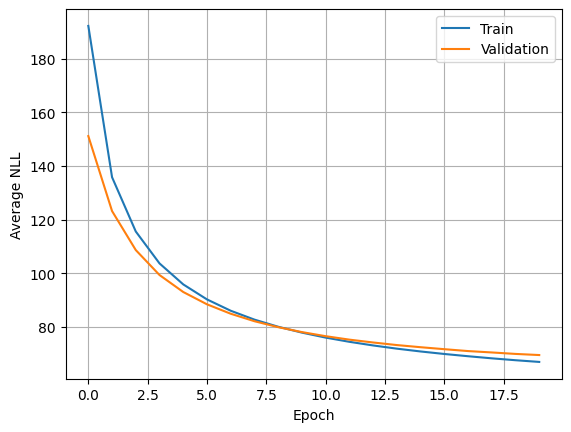

In [4]:
# Build DataLoaders from the prepared tensors
batch_size = 128

train_loader = DataLoader(train_data_id, batch_size=batch_size, shuffle=True, drop_last=False)
val_loader   = DataLoader(val_data_id, batch_size=batch_size, shuffle=False, drop_last=False)

# Model + optimizer
D = 28 * 28
H = 500

model = NADE(D=D, H=H).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

def run_epoch(loader, model, optimizer=None):
    is_train = optimizer is not None
    model.train() if is_train else model.eval()

    total_nll = 0.0
    total_count = 0

    for x in loader:
        x = x.to(device)

        logp = model(x)          # (B,)
        nll = -logp.mean()       # scalar

        if is_train:
            optimizer.zero_grad()
            nll.backward()
            optimizer.step()

        total_nll += nll.item() * x.size(0)
        total_count += x.size(0)

    return total_nll / total_count

# Training loop
epochs = 20
train_losses, val_losses = [], []

for ep in range(1, epochs + 1):
    train_nll = run_epoch(train_loader, model, optimizer=optimizer)
    val_nll = run_epoch(val_loader, model, optimizer=None)

    train_losses.append(train_nll)
    val_losses.append(val_nll)

    print(f"Epoch {ep:02d} | Train NLL: {train_nll:.4f} | Val NLL: {val_nll:.4f}")

# Plot losses
plt.figure()
plt.plot(train_losses, label="Train")
plt.plot(val_losses, label="Validation")
plt.xlabel("Epoch")
plt.ylabel("Average NLL")
plt.legend()
plt.grid(True)
plt.show()

## Task 3: OOD Detection (Log-Likelihood)

Here we use the trained NADE to compute log-likelihood scores for ID test (digits 0–4) and OOD test (digits 5–9).  
Then we compare their histograms and report AUROC using the log-likelihood as the detection score.


Average log-likelihood (ID test): -68.13400268554688
Average log-likelihood (OOD test): -99.50923156738281


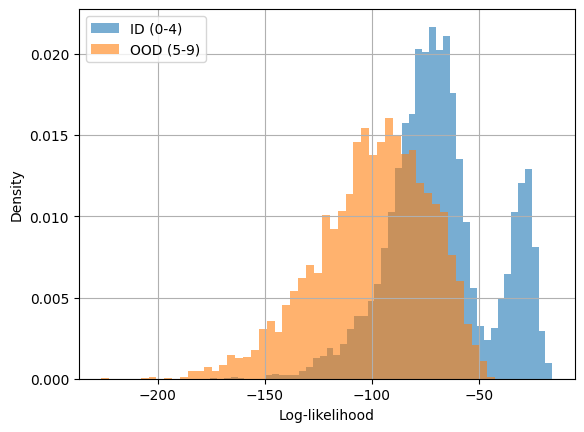

AUROC (OOD=1, using -loglik as score): 0.806790319830778


In [5]:
# Build ID test set (digits 0-4) from the original MNIST test split
id_mask_test = test_targets <= 4
id_test_data = test_data[id_mask_test]

# DataLoaders for scoring
test_batch_size = 256
id_test_loader = DataLoader(id_test_data, batch_size=test_batch_size, shuffle=False)
ood_test_loader = DataLoader(ood_data, batch_size=test_batch_size, shuffle=False)

@torch.no_grad()
def compute_loglikelihoods(loader, model):
    model.eval()
    all_logp = []
    for x in loader:
        x = x.to(device)
        logp = model(x)  # (B,)
        all_logp.append(logp.detach().cpu())
    return torch.cat(all_logp, dim=0).numpy()

id_logp = compute_loglikelihoods(id_test_loader, model)
ood_logp = compute_loglikelihoods(ood_test_loader, model)

print("Average log-likelihood (ID test):", float(id_logp.mean()))
print("Average log-likelihood (OOD test):", float(ood_logp.mean()))

# Histogram overlay
plt.figure()
plt.hist(id_logp, bins=50, alpha=0.6, label="ID (0-4)", density=True)
plt.hist(ood_logp, bins=50, alpha=0.6, label="OOD (5-9)", density=True)
plt.xlabel("Log-likelihood")
plt.ylabel("Density")
plt.legend()
plt.grid(True)
plt.show()

# AUROC (label OOD as 1, ID as 0)
y_true = np.concatenate([np.zeros_like(id_logp), np.ones_like(ood_logp)])
scores = np.concatenate([id_logp, ood_logp])  # higher score => more ID-like

# If we label OOD as 1, we want higher score to mean "more OOD" for standard AUROC.
# So we negate log-likelihood (NLL) as the anomaly score.
auroc = roc_auc_score(y_true, -scores)

print("AUROC (OOD=1, using -loglik as score):", float(auroc))


## Task 4: Generation

Here we generate a small set of new images using the trained NADE sampler.  
Since the model was trained only on digits 0–4, we expect most samples to resemble those digits (with some noise/artifacts).


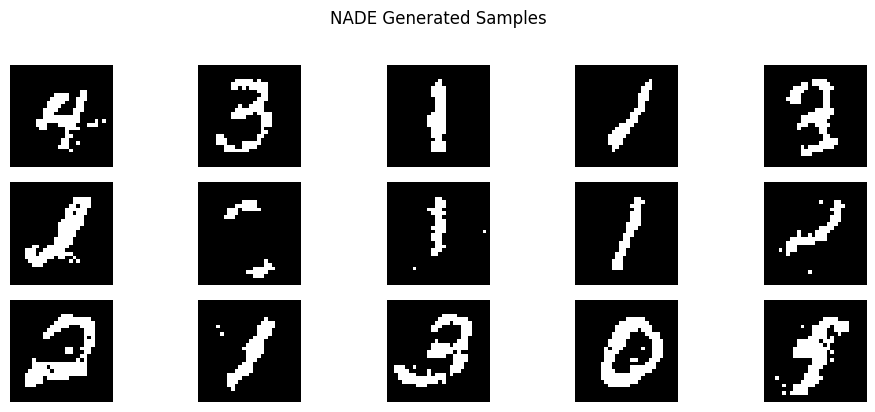

In [24]:
# Generate 15 samples
model.eval()
samples = model.sample(n_samples=15).cpu().view(-1, 28, 28)

# Visualize in a 3 x 5 grid
fig, axes = plt.subplots(3, 5, figsize=(10, 4))
for i, ax in enumerate(axes.flatten()):
    ax.imshow(samples[i], cmap="gray")
    ax.axis("off")

plt.suptitle("NADE Generated Samples", y=1.02)
plt.tight_layout()
plt.show()
